In [20]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.karate_club_graph() #Here we are importing the Karate club graph, which is alredy stored in the networkx library
print(G.number_of_edges()) #checking the number of edges
print(G.number_of_nodes()) #checking the number of nodes

78
34


In [21]:
print("The neighbours of 0 are",list(G.neighbors(0))) #prints all the neighbours of the 1st node(0)
print("The number of neighbours of 0 are",len(list(G.neighbors(0)))) #number of neighbours of 1st node, basically the degree


The neighbours of 0 are [1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 17, 19, 21, 31]
The number of neighbours of 0 are 16


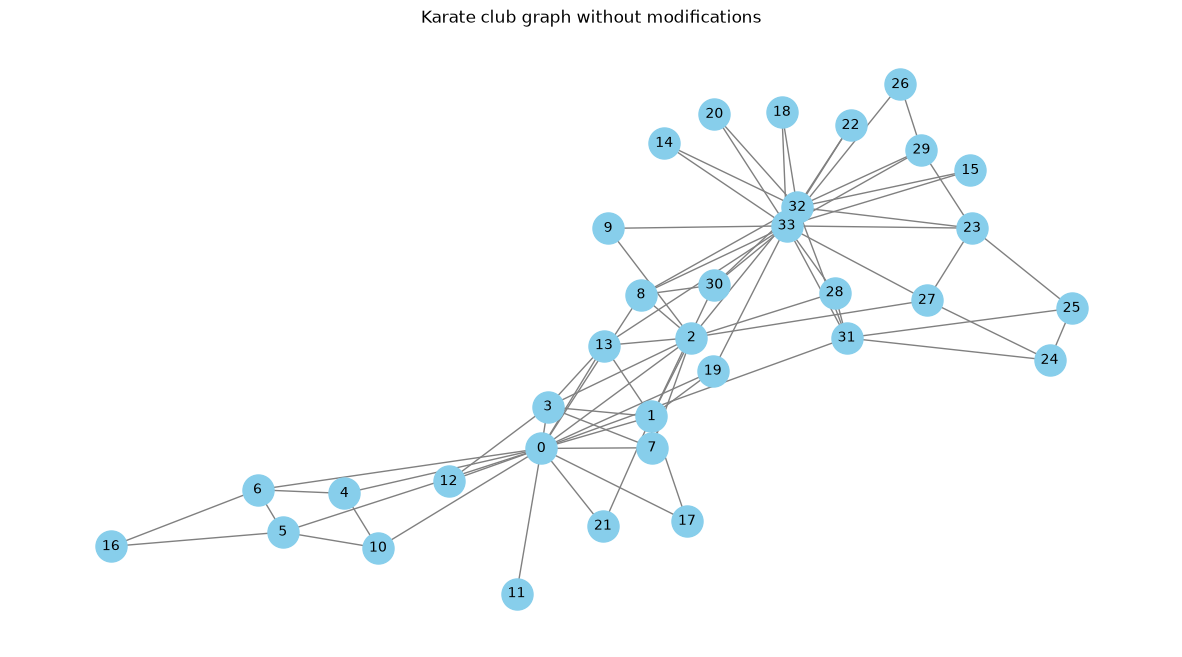

In [22]:
pos = nx.spring_layout(G,seed = 50,weight = None) #plotting the graph with the given data set as G, and seed = 50 is just showing where to start can be any integer dosn't matter
plt.figure(figsize=(15,8)) #defining the layout or the shape of the graoh
nx.draw_networkx( #viziulizes the graph
    G,
    pos = pos,
    with_labels = True, #shows the node number = basically the lables
    node_color = "skyblue", #defines the color
    node_size = 500, #the size of the node is defined 
    edge_color = "gray", #color of the edges are defined
    font_size = 10 #font size is defined here 
)
plt.title("Karate club graph without modifications")
plt.axis("off")
plt.show() #polts the graph shown below
    

In [23]:
nodes = list(G.nodes())
A = nx.to_numpy_array(G,nodelist = nodes,weight = None) # this creates a adjeceny matrix which tells us which nodes is connected to which nodes
print(A.shape)
k = A.sum(axis=1) #makes a list of the degree of each node by adding the each row in the matrix A
n = k.sum() #total degree of the graph G
m = G.number_of_edges()
print(n)
print(m)
if n == 2*m:
    print("valid values of n and m")
expected = np.outer(k,k)/(2*m) #this is the matrix of all the expected values of the randomly paired 
B = A - expected #where B is the modularity matrix 
print(B[:5,:5])
#checking if the martrix we got are valid
print("If the A matrix is symetric",np.allclose(A,A.T))
print("if the B matrix is symetric",np.allclose(B,B.T))
print("check if the B row sum is zero",np.allclose(B.sum(axis=1),0)) 

(34, 34)
156.0
78
valid values of n and m
[[-1.64102564  0.07692308 -0.02564103  0.38461538  0.69230769]
 [ 0.07692308 -0.51923077  0.42307692  0.65384615 -0.17307692]
 [-0.02564103  0.42307692 -0.64102564  0.61538462 -0.19230769]
 [ 0.38461538  0.65384615  0.61538462 -0.23076923 -0.11538462]
 [ 0.69230769 -0.17307692 -0.19230769 -0.11538462 -0.05769231]]
If the A matrix is symetric True
if the B matrix is symetric True
check if the B row sum is zero True


Finding the Eigen Vector corresponding to the highest Eigen Values

In [24]:
values,vectors = np.linalg.eigh(B)
leading_eigenvalue = values[-1]
u = vectors[:,-1]
nodes = G.nodes()
print("The leading eigenvalues is",leading_eigenvalue)
print("The eigen vector corresponding to that eigen value is\n",u)
#now we sort the vectors
x = 0
s = u.copy()
for i in s:
    if i > 0:
        s[x] = 1
    else:
        s[x] = -1
    x = x + 1
print("\n")
print(s)
positive = []
negative = []
for n,i in zip(nodes,s):
    if i==1:
        positive.append(n)
    else:
        negative.append(n)
print("\n")
print("The Nodes in the first community are",positive)
print("The nodes in the second community are",negative)
Q = (1/(4*m))*(u.T@B@u)
print(Q)
accepted = (len(positive)>0) and len(negative)>0 and Q>1e-10
print("Splict accpeted:",accepted)

The leading eigenvalues is 4.977080225729887
The eigen vector corresponding to that eigen value is
 [ 0.38754293  0.26955742  0.13189899  0.25345236  0.13400323  0.14573804
  0.14573804  0.20935954 -0.05447571 -0.04785238  0.13400323  0.07784279
  0.12874396  0.13502861 -0.13943288 -0.13943288  0.05851821  0.13197981
 -0.13943288  0.05764888 -0.13943288  0.13197981 -0.13943288 -0.21674712
 -0.0563305  -0.07540039 -0.11580257 -0.10276487 -0.06834027 -0.20629456
 -0.09626391 -0.10185678 -0.32390453 -0.36983786]


[ 1.  1.  1.  1.  1.  1.  1.  1. -1. -1.  1.  1.  1.  1. -1. -1.  1.  1.
 -1.  1. -1.  1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1. -1.]


The Nodes in the first community are [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
The nodes in the second community are [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
0.01595218021067271
Splict accpeted: True


Now printing the graph with one iteration

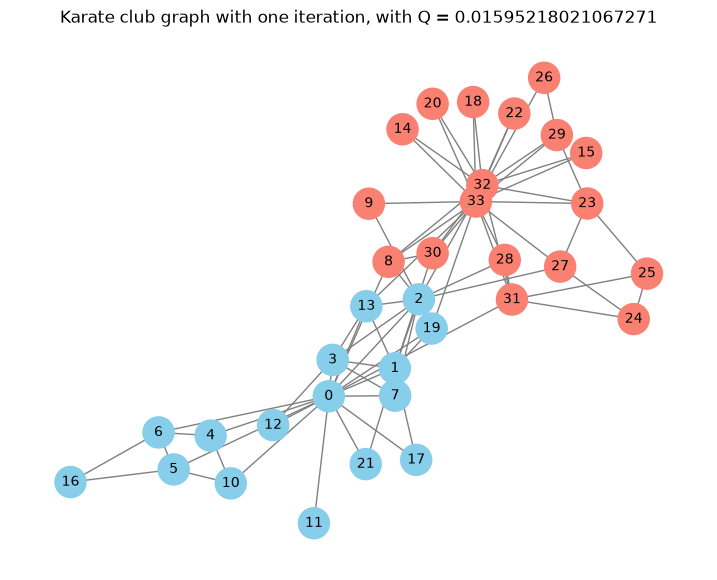

In [25]:
colors = ["skyblue" if i ==1 else "salmon" 
          for i in s]
plt.figure(figsize=(9,7))
nx.draw_networkx( #viziulizes the graph
    G,
    pos = pos,
    with_labels = True, #shows the node number = basically the lables
    nodelist = nodes,
    node_color = colors, #defines the color
    node_size = 500, #the size of the node is defined 
    edge_color = "gray", #color of the edges are defined
    font_size = 10 #font size is defined here 
)
plt.title(f"Karate club graph with one iteration, with Q = {Q}")
plt.axis("off")
plt.show()

        
    
    

Now we do the same thing but using recurssion

In [26]:
def splitting_graph(indices):
    if len(indices)<2:
        return[indices]
    B1 = B[np.ix_(indices,indices)]
    B1new = B1 - np.diag(B1.sum(axis=1))
    eigenvalues,eigenvectors = np.linalg.eigh(B1new)
    if eigenvalues[-1]<=1e-10:
        return[indices]
    u1 = eigenvectors[:,-1]
    s1 = u1.copy()
    x1 = 0
    for i1 in s1:
        if i1 > 0:
            s1[x1] = 1
        else:
            s1[x1] = -1
        x1 = x1 + 1
    positive1 = []
    negative1 = []
    for n,i in zip(indices,s1):
        if i==1:
            positive1.append(n)
        else:
            negative1.append(n)
    if len(positive1)==0 or len(negative1)==0:
        return[indices]
    Q_new = (s1 @ B1 @ s1)/(4*m)
    if Q_new<= 1e-10:
        return(indices)
    print(f"Split the {len(indices)} into two splits of {len(positive1)} + {len(negative1)};")
    return(positive1,negative1)
    

In [27]:
result_positive = splitting_graph(positive)
result_negative = splitting_graph(negative)
print(result_positive)
print(result_negative)


Split the 16 into two splits of 7 + 9;
Split the 18 into two splits of 6 + 12;
([0, 4, 5, 6, 10, 11, 16], [1, 2, 3, 7, 12, 13, 17, 19, 21])
([23, 24, 25, 27, 28, 31], [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33])


In [28]:
communities = [list(range(B.shape[0]))]
levels = [[group.copy() for group in communities]]
print(communities)
itr = 0
while True:
    next_level = []
    any_split = False
    print(f"Next level = {next_level}")
    for group in communities:
        children = splitting_graph(communities)
        print(children)
        if len(children) == 2:
            any_split = True
        next_level.extend(children)
    if not any_split:
        break
    itr = itr + 1
    communities = next_level
    levels.append([groups.copy() for groups in communities])
    print(f"\n iterations: {itr}")
    print(communities)
        

[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]
Next level = []
[[[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]]


In [29]:
#Final graph with splitted communities 
communities = [list(range(B.shape[0]))]
levels = [[group.copy() for group in communities]]
itr = 0
while True:
    next_level = []
    any_split = False
    print(f"Next level = {next_level}")
    for group in communities:
        children = splitting_graph(group)
        print(children)
        if len(children) == 2:
            any_split = True
        next_level.extend(children)
    if not any_split:
        break
    itr = itr + 1
    communities = next_level
    levels.append([group.copy() for group in communities])
    print(f"\n iterations: {itr}")
    print(communities)

Next level = []
Split the 34 into two splits of 16 + 18;
([0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33])

 iterations: 1
[[0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21], [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]]
Next level = []
Split the 16 into two splits of 7 + 9;
([0, 4, 5, 6, 10, 11, 16], [1, 2, 3, 7, 12, 13, 17, 19, 21])
Split the 18 into two splits of 6 + 12;
([23, 24, 25, 27, 28, 31], [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33])

 iterations: 2
[[0, 4, 5, 6, 10, 11, 16], [1, 2, 3, 7, 12, 13, 17, 19, 21], [23, 24, 25, 27, 28, 31], [8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]]
Next level = []
[[0, 4, 5, 6, 10, 11, 16]]
Split the 9 into two splits of 4 + 5;
([1, 17, 19, 21], [2, 3, 7, 12, 13])
[[23, 24, 25, 27, 28, 31]]
[[8, 9, 14, 15, 18, 20, 22, 26, 29, 30, 32, 33]]

 iterations: 3
[[0, 4, 5, 6, 10, 11, 16], [1, 17, 19, 21], [2, 3, 7, 12, 13], [23, 24, 2

In [30]:
#calculating matrices
node_order = list(nodes)  # Use the same node order you used to build B

metric_functions = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

scores_by_iteration = {}

for iteration, groups in enumerate(levels):
    scores_by_iteration[iteration] = {
        name: {} for name in metric_functions
    }

    for group in groups:
        community_nodes = [node_order[i] for i in group]
        H = G.subgraph(community_nodes)

        for name, calculate in metric_functions.items():
            scores_by_iteration[iteration][name].update(calculate(H))

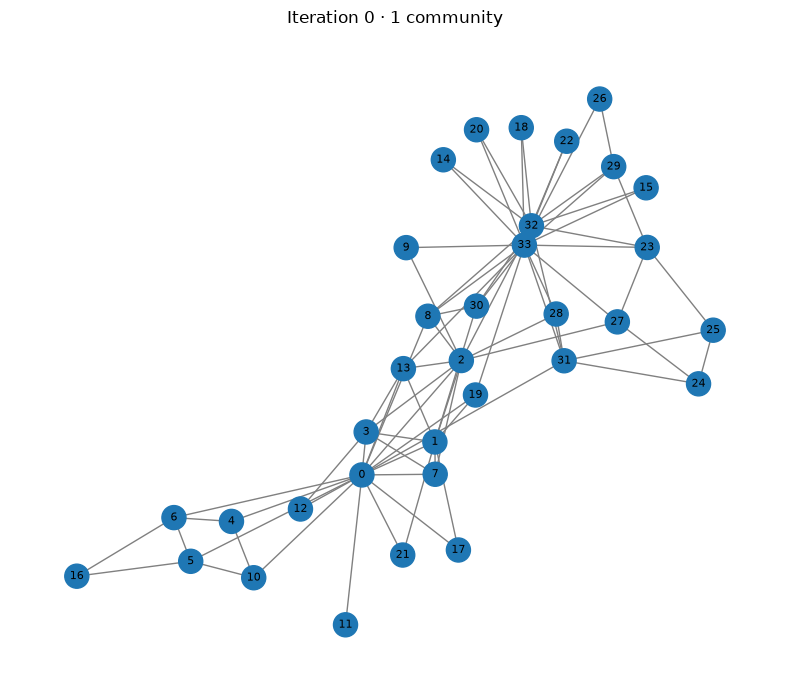

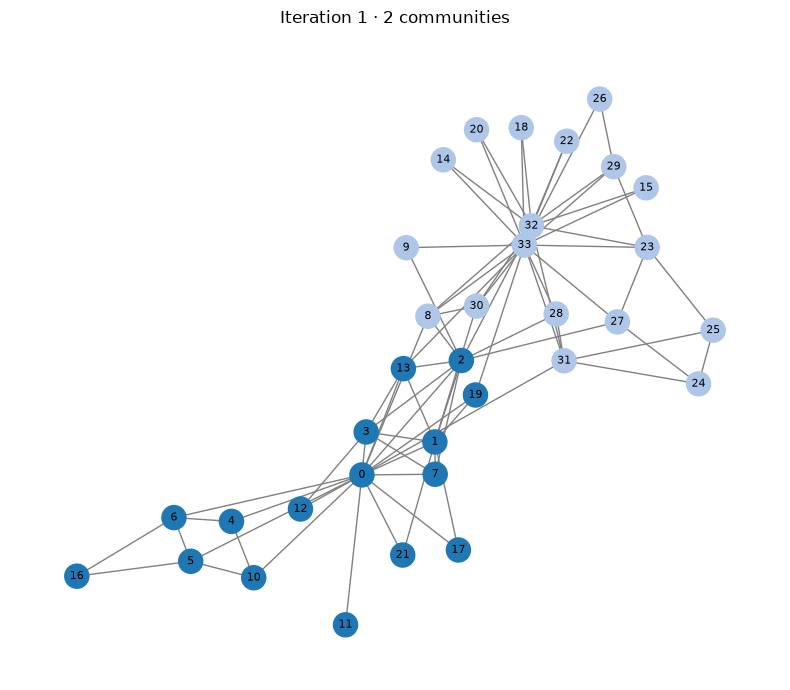

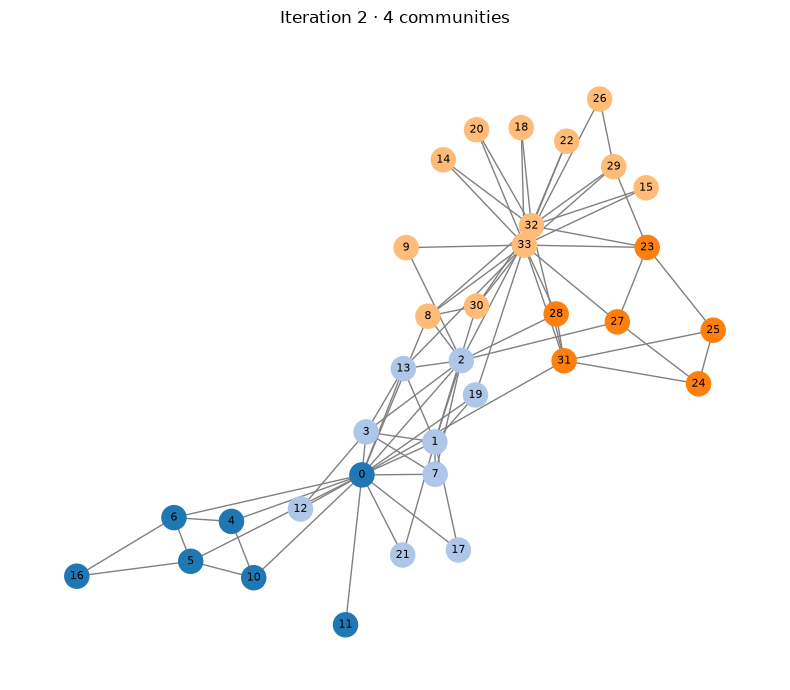

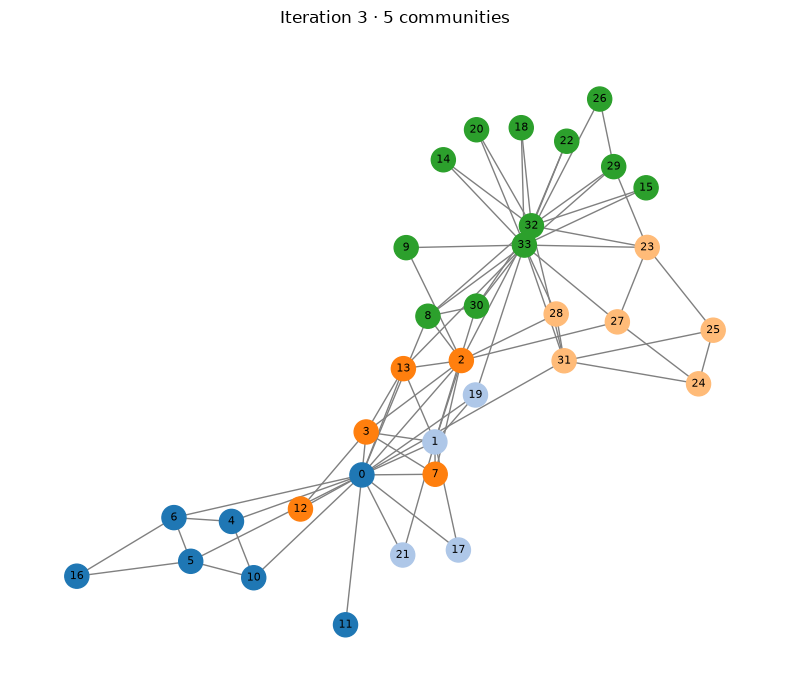

In [31]:
#here plotting each iteration
from matplotlib.backends.backend_pdf import PdfPages
from IPython.display import HTML, display

with PdfPages("community_iterations.pdf") as pdf:
    for iteration, groups in enumerate(levels):
        if iteration > 0:
            display(HTML('<div style="height: 40px"></div>'))

        fig, ax = plt.subplots(figsize=(8, 7))
        color_by_node = {}

        for community_id, group in enumerate(groups):
            for i in group:
                color_by_node[node_order[i]] = palette[
                    community_id % len(palette)
                ]

        nx.draw_networkx(
            G,
            pos=pos,
            nodelist=node_order,
            node_color=[color_by_node[node] for node in node_order],
            node_size=300,
            font_size=8,
            edge_color="gray",
            ax=ax,
        )

        label = "community" if len(groups) == 1 else "communities"
        ax.set_title(f"Iteration {iteration} · {len(groups)} {label}", pad=15)
        ax.set_axis_off()

        fig.tight_layout()
        pdf.savefig(fig)
        plt.show()
        plt.close(fig)

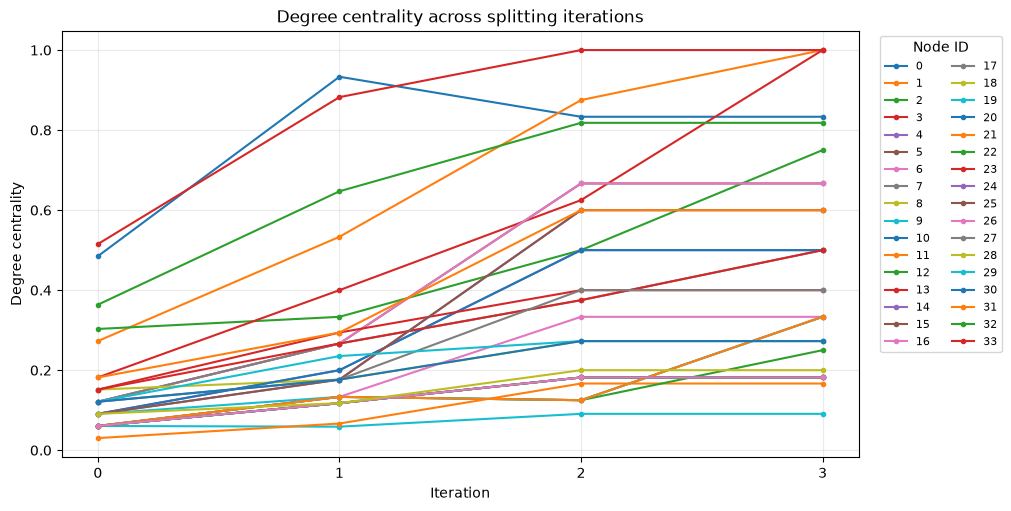

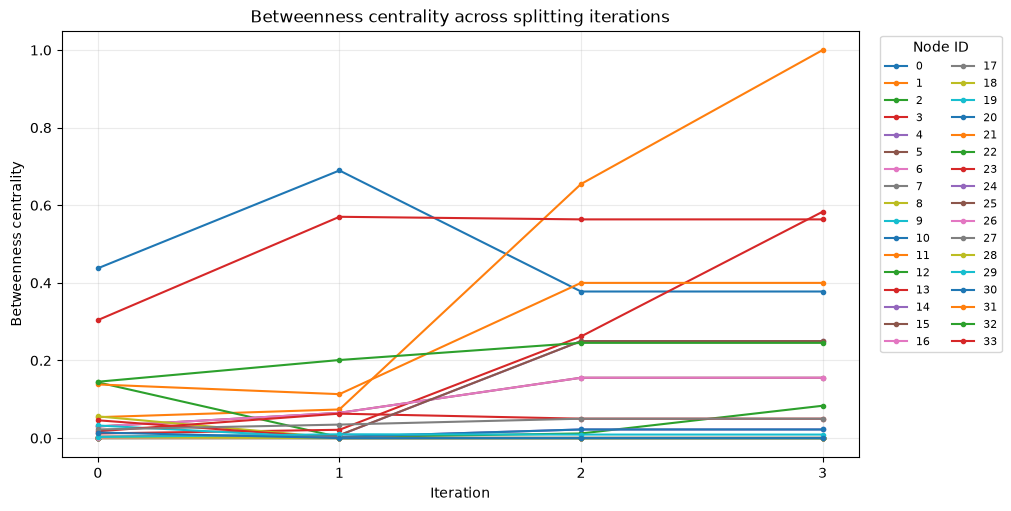

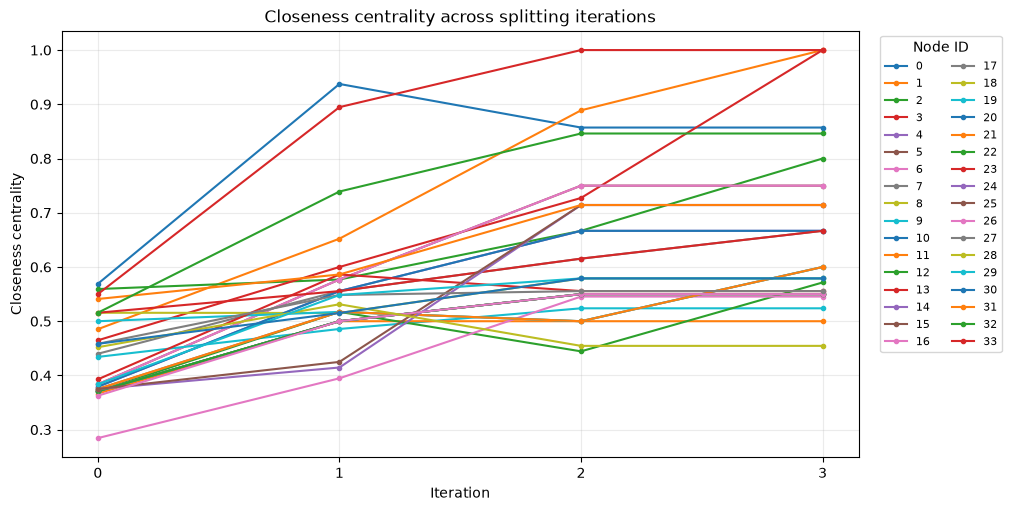

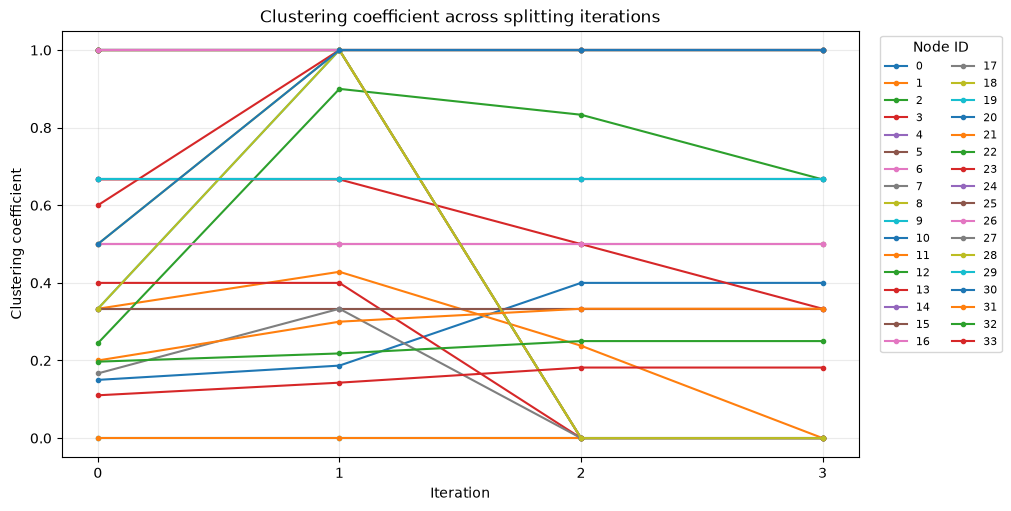

In [32]:
#We are plotting the matrices for each iteration
iterations = list(scores_by_iteration)

for name in metric_functions:
    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

    for node in node_order:
        values = [
            scores_by_iteration[iteration][name][node]
            for iteration in iterations
        ]
        ax.plot(iterations, values, marker="o", markersize=3, label=str(node))

    ax.set_title(f"{name} across splitting iterations")
    ax.set_xlabel("Iteration")
    ax.set_ylabel(name)
    ax.set_xticks(iterations)
    ax.legend(title="Node ID", bbox_to_anchor=(1.02, 1),
              loc="upper left", ncol=2, fontsize=8)
    ax.grid(alpha=0.25)
    plt.show()

Discussion:

When we first split the graph using the modularity score, it divides the graph into two groups, which are then subdivided into many subgroups. At each iteration, the eigenvectors of the modularity matrix tell us whether to split or not. We split only if the modularity increases. By the end, we have reached five communities. Splitting further wouldn’t make sense because it doesn’t give us a better modularity score, which is what we use to judge whether to split.

The graphs above tell us that a member’s role depends on the community in which they are measured. Degree centrality tells us how many people a member is connected to within the community, divided by the number of people in the community excluding that member. The number of people in the community decreases faster than the number of nodes the member is connected to within it, so the degree centrality generally increases. As for closeness centrality, it also increases with each split. Higher closeness centrality tells us how fast information could spread to others if it were given to someone. Having higher closeness centrality makes someone a good spreader, so in our graph, nodes 3, 33, and 1 are good spreaders.

Betweenness centrality tells us how often a node appears on the shortest path between two other nodes. Higher betweenness centrality helps us identify which members connect different parts of the group and how their roles change after splitting. In our graph, node 1 is the strongest bridge between the communities obtained after all five iterations.

Nodes 0 and 33 are the most central members across all the splits. Node 0 has high degree centrality and high closeness centrality, while node 33’s degree centrality peaked just after the second iteration. This means it could reach everyone in its community directly. Node 33 also has high closeness centrality.

Community structure changes which connections and paths are counted. In a smaller community, a member may be directly connected to a larger fraction of the community, raising their degree centrality. They may also be fewer steps away from other members of their community, raising their closeness centrality. Betweenness depends on which shortest paths remain within the group, while clustering depends on whether the neighbours who stay together are connected to one another.